In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import factorial
from scipy.stats import *
import random
import pandas as pd
# for reproducability
np.random.seed(42)

In [8]:
def CTMC(Q, initial_state, max_time):

    num_states = Q.shape[1] # 1 column per state in state space
    states = [initial_state] # initialize list of states traversed
    t_n_list = [0.0]   # initialize list of time reach next state

    current_state = initial_state
    current_time = 0.0

    while current_time < max_time:
        # time before jumping to next state, flow out of state
        lmbda = -Q[current_state, current_state]

        # sample time next state reached
        #   ~ Exp(wait_rate)
        t_n = np.random.exponential(1.0 / lmbda)


        if current_time + t_n >= max_time: # stop if past max time
            break
        current_time += t_n  # update time

        # compute probabilities for next jump
        #   q(i,j)/lmbda_i
        jump_rates = np.copy(Q[current_state, :])
        jump_rates[current_state] = 0.0  # zero out the diagonal elements
        probabilities = jump_rates / lmbda

        # sample next state based on transition probabilities calculated above
        next_state = np.random.choice(num_states, p=probabilities)

        t_n_list.append(current_time)   # jump times
        states.append(next_state)  # states reached

        current_state = next_state

    return np.array(states), np.array(t_n_list)

In [9]:
def fraction_in_state_1(num_sims, Q, max_time, time_grid):
  state_1_counts = np.zeros_like(time_grid)
  for _ in range(num_sims):
      # choose initial condition based on given probabilities
      # P(X_0 = 1) = 1/3,  state 1 = index 0
      # P(X_0 = 2) = 2/3,  state 2 = index 1
      ic = np.random.choice([0,1,2,3], p=[1/3, 2/3, 0, 0])

      # simulate MC with the randomly selected initial condition
      states, times = CTMC(Q, initial_state=ic, max_time=max_time)

      # find state at each time in grid
      idx = np.searchsorted(times, time_grid, side='right') - 1
      grid_states = states[idx]
      state_1_counts += (grid_states == 0).astype(float)  # state 1 = index 0

  return state_1_counts / num_sims

# theoretical probability from part d
def fraction_theoretical(t):
  return 0.25 + (np.exp(-t) / 12)

fraction_theoretical_vectorized = np.vectorize(fraction_theoretical)

In [10]:
Q = np.array([
    [-1, 0, 0, 1],
    [1, -1, 0, 0],
    [0, 1, -1, 0],
    [0, 0, 1, -1]
])

max_time = 5
time_grid = np.linspace(0, max_time, 200)

state_1_fraction_100 = fraction_in_state_1(100, Q, 5, time_grid)
state_1_fraction_1k = fraction_in_state_1(1000, Q, 5, time_grid)
state_1_fraction_10k = fraction_in_state_1(10000, Q, 5, time_grid)
state_1_fraction_100k = fraction_in_state_1(100000, Q, 5, time_grid)

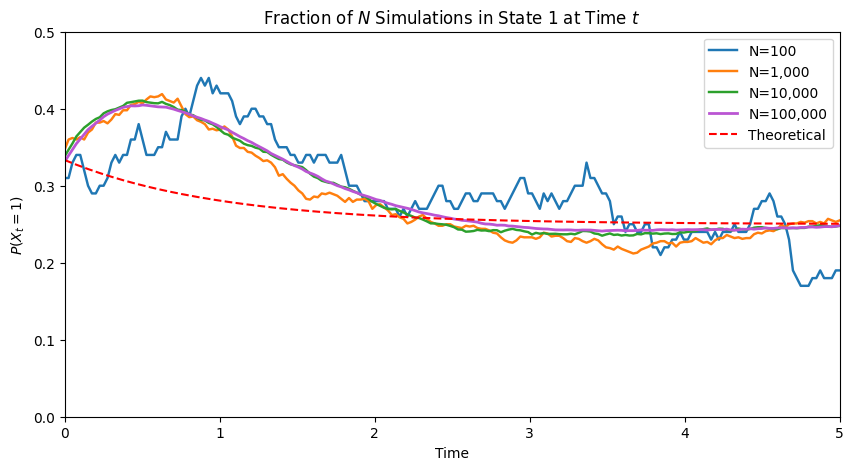

In [11]:
plt.figure(figsize = (10,5))

plt.plot(time_grid, state_1_fraction_100, label = 'N=100',
         linewidth = 1.75)
plt.plot(time_grid, state_1_fraction_1k, label = 'N=1,000',
         linewidth = 1.75)
plt.plot(time_grid, state_1_fraction_10k, label = 'N=10,000',
         linewidth = 1.75)
plt.plot(time_grid, state_1_fraction_100k, label = 'N=100,000',
         linewidth = 2, color = 'mediumorchid')
plt.plot(time_grid, fraction_theoretical_vectorized(time_grid),label = 'Theoretical',
         linewidth = 1.5, linestyle = '--', color = 'r')



plt.xlabel('Time')
plt.ylabel(r'$P(X_t = 1)$')
plt.xlim(0,5)
plt.ylim(0,0.5)
plt.legend()
plt.title(rf'Fraction of $N$ Simulations in State 1 at Time $t$')

plt.show()